In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
artists = pd.read_json('artists.jsonl', lines=True)
genres_to_filter = ['pop', 'trap', 'rap', 'rock', 'metal', 'hip hop']
divided_songs = {}

In [3]:
for genre in genres_to_filter:
    divided_songs[genre] = pd.read_json(f'annotaded_tracks/{genre}_annotated.json', orient='records', lines=True)

In [4]:
import torch, torchvision
from torchvision import transforms
import torch.nn as nn
import torch.optim as optim
import torch.functional as F
import numpy as np
import pandas as pd
import torch.utils.data as data
import seaborn as sns
import matplotlib.pyplot as plt
from NN import RegresionModel, RegresionModelSimple, RegresionModelBig, RegresionModelManyLayers
from sklearn.preprocessing import StandardScaler
from sklearn import preprocessing

### Selekcja atrybutów

Selekcja odbędzie się na podstawie licznej grupy pop.

Tak jak zostało ustalone przy początkowej analizie część atrybuty koreluje ze sobą:
- loudness i energy
- acousticness i energy
- speechiness i explicit
- valence i danceability
  
Z tego powodu atrybuty loudness, valence, excplicit, acousticness nie będą używane do trenowania modelów.

Również nie będzie używany atrybut intrumentalness z powodu swojego nieprzydatnego rozkładu.

#### Sortowanie atrybutów względem czasu

Atrybuty są sortowane względem czasu, żeby ewentualnie wycwycić zachodzące w nich trędy

In [5]:
data_raw = divided_songs['pop'].copy()
data_raw['release_date'] = pd.to_datetime(data_raw['release_date'], errors='coerce', exact=False)
data_raw = data_raw.sort_values(by='release_date')
data_raw = data_raw.drop(["id", 'name', 'explicit', 'id_artist', 'key', 'release_date', 'popularity', \
                          'loudness', 'acousticness', 'explicit', 'valence', 'duration_ms', 'instrumentalness'], axis=1)

In [6]:
features = ['danceability', 'energy', 'speechiness', \
            'liveness', 'tempo']


In [7]:
data_raw.columns

Index(['danceability', 'energy', 'speechiness', 'liveness', 'tempo',
       'coherence'],
      dtype='object')

In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
# for f in  features:
data_raw.iloc[:, :-1] = scaler.fit_transform(data_raw.iloc[:, :-1])

In [9]:
data_raw.loc[:, :] = data_raw.loc[:, :].astype(float)

### Przygotowanie zbioru trenującego i walidacyjnego

In [11]:
train_data = torch.from_numpy(data_raw.values[:int(data_raw.shape[0] * 2/3),:-1]).float()
train_targets = torch.from_numpy(data_raw.values[:int(data_raw.shape[0] * 2/3),-1]).float()

valid_data = torch.from_numpy(data_raw.values[int(data_raw.shape[0] * 2/3):,:-1]).float()
valid_targets = torch.from_numpy(data_raw.values[int(data_raw.shape[0] * 2/3):,-1]).float()


In [13]:
train_data

tensor([[-0.2441, -1.4268, -0.6149, -0.3896, -0.8914],
        [-0.8623, -0.4073, -0.5523, -0.2015, -1.7523],
        [-0.3747, -1.7966, -0.5848, -0.3645, -0.8847],
        ...,
        [ 0.0031, -0.8821, -0.6197, -0.2767, -1.2320],
        [-0.0999, -1.2818, -0.5981, -0.4146, -0.9294],
        [-0.0106, -2.0514, -0.5029, -0.6598, -0.8650]])

In [14]:
train_dataset = data.TensorDataset(train_data, train_targets)
valid_dataset = data.TensorDataset(valid_data, valid_targets)

In [15]:
data_loader_train = data.DataLoader(train_dataset, batch_size=256, shuffle=True)
data_loader_valid = data.DataLoader(valid_dataset, batch_size=256, shuffle=True)

In [16]:
device = torch.device('cpu')

In [17]:
def get_valid_loss(model, data_loader):
    criterion = nn.MSELoss()
    epoch_losses = []
    ouputs = []
    model.eval()
    with torch.no_grad():
        device_cpu = torch.device('cpu')
        for x, labels in data_loader:
            x, labels = x.to(device), labels.to(device)
            output = model(x)
            output = output.to(device_cpu)
            labels = labels.to(device_cpu)
            loss = criterion(output, labels)
            epoch_losses.append(loss.item())
    return epoch_losses

### Selekcja atrybutów dla siecie neuronowej

Selekcja zostanwyliczona poprzez śledzenie gradientów w sieci.

In [19]:
device = torch.device('cpu')
model = RegresionModelSimple(train_data.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)

iters = []
losses_train = []
losses_valid = []

for n in range(1000):
    epoch_losses = []
    out = 0
    for x, labels in data_loader_train:
        x, labels = x.to(device), labels.to(device)
        model.train()
        out = model(x)
        out = out.squeeze(dim=1)
        loss = criterion(out, labels)
        optimizer.zero_grad()

        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)
    print(f"Train epoch {n} loss {loss_mean_train}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([39])) that is different to the input size (torch.Size([39, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Train epoch 0 loss 21853.769972278227
Valid epoch 0 loss 24982.312744140625
Train epoch 1 loss 21966.123487903227
Valid epoch 1 loss 25021.143920898438
Train epoch 2 loss 21860.908329133064
Valid epoch 2 loss 25087.82958984375
Train epoch 3 loss 21893.697265625
Valid epoch 3 loss 24802.436767578125
Train epoch 4 loss 21863.113155241936
Valid epoch 4 loss 24828.932250976562
Train epoch 5 loss 21889.23160282258
Valid epoch 5 loss 24857.23046875
Train epoch 6 loss 21916.809349798386
Valid epoch 6 loss 24742.498657226562
Train epoch 7 loss 21826.841481854837
Valid epoch 7 loss 24700.614013671875
Train epoch 8 loss 21817.410471270163
Valid epoch 8 loss 25028.917602539062
Train epoch 9 loss 21773.65291078629
Valid epoch 9 loss 24821.1953125
Train epoch 10 loss 21870.542464717742
Valid epoch 10 loss 24999.69091796875
Train epoch 11 loss 21809.299584173386
Valid epoch 11 loss 24771.390625
Train epoch 12 loss 21828.91185735887
Valid epoch 12 loss 24730.235961914062
Train epoch 13 loss 21869.102

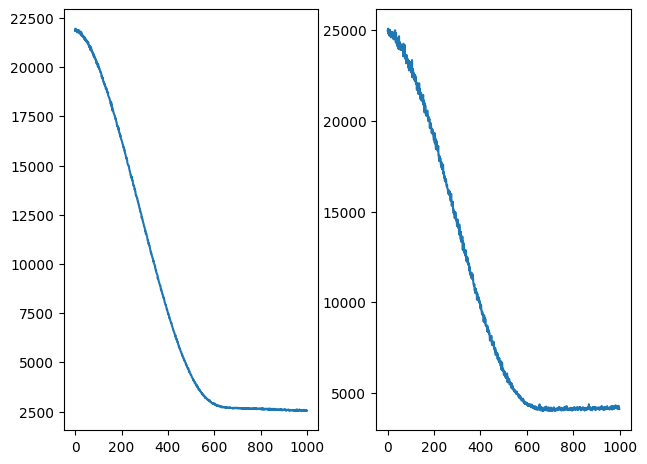

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2)
plt.tight_layout()
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])

In [36]:
y_pred = model(torch.tensor(valid_data)).detach().numpy()

/tmp/ipykernel_12306/3061495740.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(valid_data)).detach().numpy()


In [37]:
print(f'MAE: {mean_absolute_error(valid_targets, y_pred)}')
print(f'MSE: {mean_squared_error(valid_targets, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(valid_targets, y_pred))}')

MAE: 49.935523986816406
MSE: 4159.35693359375
RMSE: 64.49308013916016


/tmp/ipykernel_12306/2138519429.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test_tensor = torch.tensor(valid_data, dtype=torch.float32)


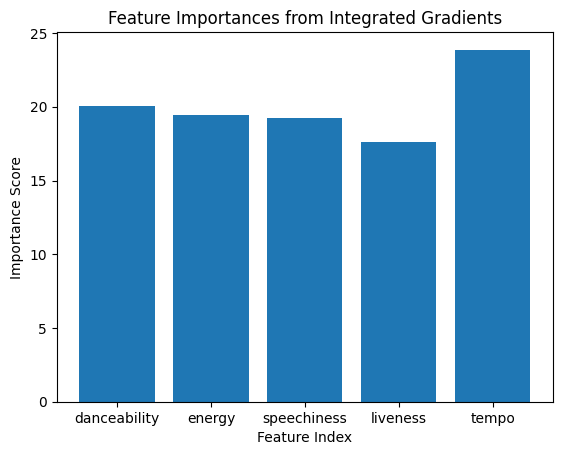

In [24]:
from captum.attr import IntegratedGradients

ig = IntegratedGradients(model)

X_test_tensor = torch.tensor(valid_data, dtype=torch.float32)

target_class = 0
def compute_attributions(sample):
    attributions, _ = ig.attribute(sample.unsqueeze(0), target=target_class, return_convergence_delta=True)
    return attributions.squeeze(0).detach().numpy()

attributions = np.array([compute_attributions(sample) for sample in X_test_tensor])

feature_importance = np.mean(np.abs(attributions), axis=0)

plt.bar(range(len(feature_importance)), feature_importance)
plt.xlabel('Feature Index')
plt.ylabel('Importance Score')
plt.title('Feature Importances from Integrated Gradients')
plt.xticks([i for i in range(data_raw.shape[1]-1)], np.array(data_raw.columns[:-1]))
plt.show()

## Gradient Boost

In [25]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error


model_grad = GradientBoostingRegressor()

# Train the model
model_grad.fit(train_data, train_targets)

# Predict on the training set
y_train_pred = model_grad.predict(valid_data)


In [27]:
print(f'MAE: {mean_absolute_error(valid_targets, y_train_pred)}')
print(f'MSE: {mean_squared_error(valid_targets, y_train_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(valid_targets, y_train_pred))}')

MAE: 47.514411535289426
MSE: 3772.5062884618646
RMSE: 61.42073174801701


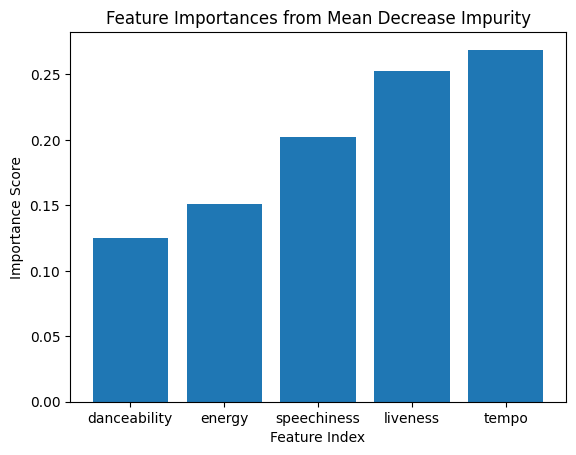

In [40]:
feature_importance = model_grad.feature_importances_
sorted_idx = np.argsort(feature_importance)

plt.bar(range(len(feature_importance)), feature_importance[sorted_idx])
plt.xlabel('Feature Index')
plt.ylabel('Importance Score')
plt.title('Feature Importances from Mean Decrease Impurity')
plt.xticks([i for i in range(data_raw.shape[1]-1)], np.array(data_raw.columns[:-1]))
plt.show()


plt.show()

### Wnioski z selekcji

Po wykresach istotności widać, że wszystkie atrybuty mają wpływ na przewidywania modelów, pomimo że niektóre wpływają bardziej od innych.

## Strojenie hiperparametrów - sieć neuronowa

### Mała sieć

In [41]:
device = torch.device('cpu')
model = RegresionModelSimple(train_data.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)

iters = []
losses_train = []
losses_valid = []

for n in range(1000):
    epoch_losses = []
    out = 0
    for x, labels in data_loader_train:
        x, labels = x.to(device), labels.to(device)
        model.train()
        out = model(x)
        out = out.squeeze(dim=1)
        loss = criterion(out, labels)
        optimizer.zero_grad()

        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)
    print(f"Train epoch {n} loss {loss_mean_train}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([39])) that is different to the input size (torch.Size([39, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Train epoch 0 loss 21875.20621219758
Valid epoch 0 loss 25180.143188476562
Train epoch 1 loss 21963.529989919356
Valid epoch 1 loss 25042.328369140625
Train epoch 2 loss 21863.359690020163
Valid epoch 2 loss 24585.965087890625
Train epoch 3 loss 21991.703566028227
Valid epoch 3 loss 24813.767456054688
Train epoch 4 loss 21926.02620967742
Valid epoch 4 loss 25052.031494140625
Train epoch 5 loss 21859.12197580645
Valid epoch 5 loss 24930.86572265625
Train epoch 6 loss 21864.21566280242
Valid epoch 6 loss 24845.496459960938
Train epoch 7 loss 21867.2892515121
Valid epoch 7 loss 24949.332275390625
Train epoch 8 loss 21855.401713709678
Valid epoch 8 loss 24871.619018554688
Train epoch 9 loss 21856.049332157258
Valid epoch 9 loss 24993.174560546875
Train epoch 10 loss 21923.362084173386
Valid epoch 10 loss 24790.6181640625
Train epoch 11 loss 21899.855846774193
Valid epoch 11 loss 24564.253173828125
Train epoch 12 loss 21894.486265120966
Valid epoch 12 loss 25012.046630859375
Train epoch 13 

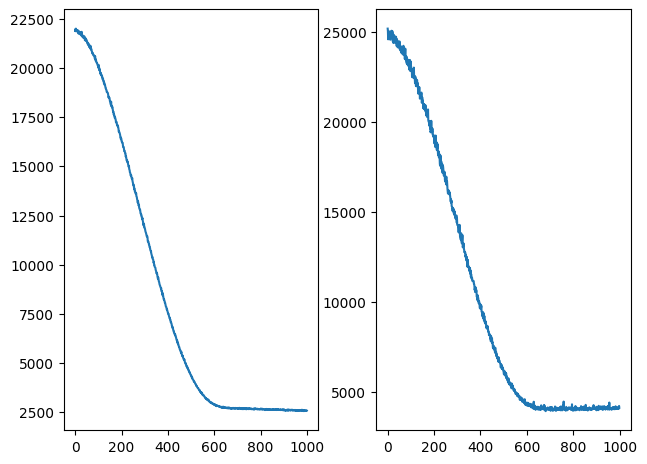

In [42]:
fig, (ax1, ax2) = plt.subplots(1, 2)
plt.tight_layout()
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])

In [43]:
y_pred = model(torch.tensor(valid_data)).detach().numpy()

/tmp/ipykernel_12306/3061495740.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(valid_data)).detach().numpy()


In [44]:
print(f'MAE: {mean_absolute_error(valid_targets, y_pred)}')
print(f'MSE: {mean_squared_error(valid_targets, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(valid_targets, y_pred))}')

MAE: 49.749595642089844
MSE: 4118.0634765625
RMSE: 64.1721420288086


### Większa sieć z techniką dropout

In [45]:
device = torch.device('cpu')
model = RegresionModel(train_data.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)

iters = []
losses_train = []
losses_valid = []

for n in range(1000):
    epoch_losses = []
    out = 0
    for x, labels in data_loader_train:
        x, labels = x.to(device), labels.to(device)
        model.train()
        out = model(x)
        out = out.squeeze(dim=1)
        loss = criterion(out, labels)
        optimizer.zero_grad()

        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)
    print(f"Train epoch {n} loss {loss_mean_train}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([39])) that is different to the input size (torch.Size([39, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Train epoch 0 loss 21913.92408014113
Valid epoch 0 loss 24747.0615234375
Train epoch 1 loss 21842.338394657258
Valid epoch 1 loss 24619.320678710938
Train epoch 2 loss 21816.63778981855
Valid epoch 2 loss 25202.035766601562
Train epoch 3 loss 21943.37890625
Valid epoch 3 loss 24812.466918945312
Train epoch 4 loss 21969.405619959678
Valid epoch 4 loss 24632.907958984375
Train epoch 5 loss 21830.404926915322
Valid epoch 5 loss 25187.662353515625
Train epoch 6 loss 21912.651713709678
Valid epoch 6 loss 24914.819091796875
Train epoch 7 loss 21839.283518145163
Valid epoch 7 loss 24860.88232421875
Train epoch 8 loss 21759.18724798387
Valid epoch 8 loss 24990.20703125
Train epoch 9 loss 21870.320690524193
Valid epoch 9 loss 24777.191528320312
Train epoch 10 loss 21734.158707157258
Valid epoch 10 loss 24875.529907226562
Train epoch 11 loss 21830.84740423387
Valid epoch 11 loss 24628.704345703125
Train epoch 12 loss 21789.106098790322
Valid epoch 12 loss 24661.852294921875
Train epoch 13 loss 2

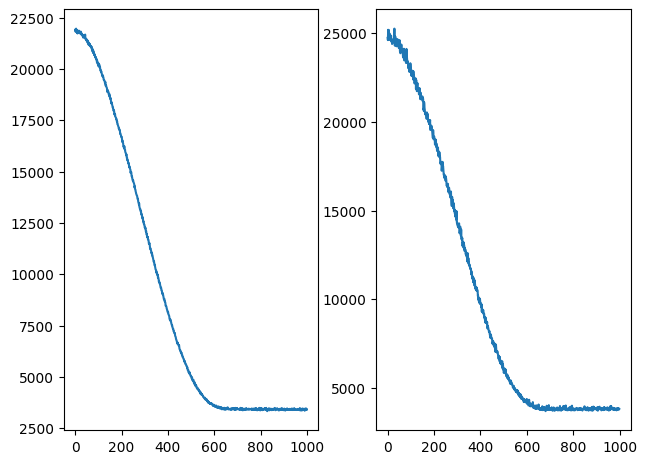

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2)
plt.tight_layout()
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])

In [47]:
y_pred = model(torch.tensor(valid_data)).detach().numpy()

/tmp/ipykernel_12306/3061495740.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(valid_data)).detach().numpy()


In [48]:
print(f'MAE: {mean_absolute_error(valid_targets, y_pred)}')
print(f'MSE: {mean_squared_error(valid_targets, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(valid_targets, y_pred))}')

MAE: 47.75594711303711
MSE: 3819.54296875
RMSE: 61.802452087402344


### Sieć z wiekszą ilością powłok

In [49]:
device = torch.device('cpu')
model = RegresionModelManyLayers(train_data.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)

iters = []
losses_train = []
losses_valid = []

for n in range(1000):
    epoch_losses = []
    out = 0
    for x, labels in data_loader_train:
        x, labels = x.to(device), labels.to(device)
        model.train()
        out = model(x)
        out = out.squeeze(dim=1)
        loss = criterion(out, labels)
        optimizer.zero_grad()

        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)
    print(f"Train epoch {n} loss {loss_mean_train}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

AttributeError: 'RegresionModelManyLayers' object has no attribute 'layer2'

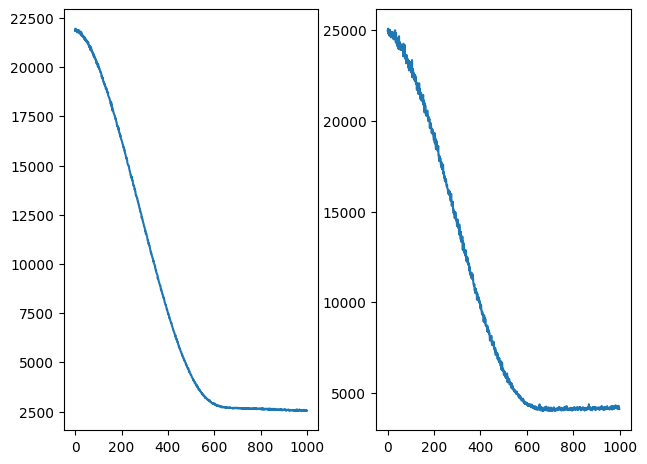

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2)
plt.tight_layout()
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])

In [ ]:
y_pred = model(torch.tensor(valid_data)).detach().numpy()

/tmp/ipykernel_12306/3061495740.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(valid_data)).detach().numpy()


In [ ]:
print(f'MAE: {mean_absolute_error(valid_targets, y_pred)}')
print(f'MSE: {mean_squared_error(valid_targets, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(valid_targets, y_pred))}')

MAE: 49.935523986816406
MSE: 4159.35693359375
RMSE: 64.49308013916016


### Sieć z wieloma neuronami w powłoce

In [ ]:
device = torch.device('cpu')
model = RegresionModelBig(train_data.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)

iters = []
losses_train = []
losses_valid = []

for n in range(1000):
    epoch_losses = []
    out = 0
    for x, labels in data_loader_train:
        x, labels = x.to(device), labels.to(device)
        model.train()
        out = model(x)
        out = out.squeeze(dim=1)
        loss = criterion(out, labels)
        optimizer.zero_grad()

        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)
    print(f"Train epoch {n} loss {loss_mean_train}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([39])) that is different to the input size (torch.Size([39, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Train epoch 0 loss 21853.769972278227
Valid epoch 0 loss 24982.312744140625
Train epoch 1 loss 21966.123487903227
Valid epoch 1 loss 25021.143920898438
Train epoch 2 loss 21860.908329133064
Valid epoch 2 loss 25087.82958984375
Train epoch 3 loss 21893.697265625
Valid epoch 3 loss 24802.436767578125
Train epoch 4 loss 21863.113155241936
Valid epoch 4 loss 24828.932250976562
Train epoch 5 loss 21889.23160282258
Valid epoch 5 loss 24857.23046875
Train epoch 6 loss 21916.809349798386
Valid epoch 6 loss 24742.498657226562
Train epoch 7 loss 21826.841481854837
Valid epoch 7 loss 24700.614013671875
Train epoch 8 loss 21817.410471270163
Valid epoch 8 loss 25028.917602539062
Train epoch 9 loss 21773.65291078629
Valid epoch 9 loss 24821.1953125
Train epoch 10 loss 21870.542464717742
Valid epoch 10 loss 24999.69091796875
Train epoch 11 loss 21809.299584173386
Valid epoch 11 loss 24771.390625
Train epoch 12 loss 21828.91185735887
Valid epoch 12 loss 24730.235961914062
Train epoch 13 loss 21869.102

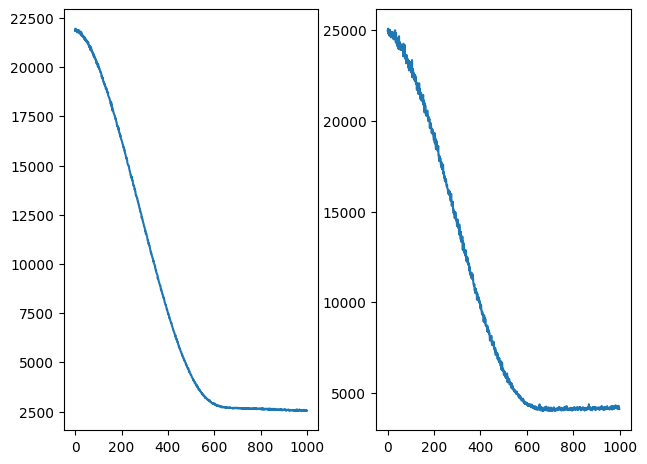

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2)
plt.tight_layout()
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])

In [ ]:
y_pred = model(torch.tensor(valid_data)).detach().numpy()

/tmp/ipykernel_12306/3061495740.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(valid_data)).detach().numpy()


In [ ]:
print(f'MAE: {mean_absolute_error(valid_targets, y_pred)}')
print(f'MSE: {mean_squared_error(valid_targets, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(valid_targets, y_pred))}')

MAE: 49.935523986816406
MSE: 4159.35693359375
RMSE: 64.49308013916016


## Strojenie hiperparametrów Gradient Boosting

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier


gb = GradientBoostingClassifier()

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 0.9, 1.0]
}

grid_search = GridSearchCV(estimator=gb, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')
grid_search.fit(train_data, train_targets)

print("Najlepsze parametry: ", grid_search.best_params_)
print("Najlepszy wynik: ", grid_search.best_score_)
